In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import seaborn as sns

In [ ]:
Train = pd.read_csv('/test_energy_data.csv')
Test = pd.read_csv('/test_energy_data.csv')

print("Train:", Train.shape)
display(Train.head())


Train: (100, 7)


,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,24563,15,4,28.52,Weekday,2865.57
1,Commercial,27583,56,23,23.07,Weekend,4283.80
2,Commercial,45313,4,44,33.56,Weekday,5067.83
3,Residential,41625,84,17,27.39,Weekend,4624.30
4,Residential,36720,58,47,17.08,Weekday,4820.59


In [ ]:
print("Test:", Test.shape)
display(Test.head())

Test: (1000, 7)


,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17


In [ ]:
Train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        100 non-null    object 
 1   Square Footage       100 non-null    int64  
 2   Number of Occupants  100 non-null    int64  
 3   Appliances Used      100 non-null    int64  
 4   Average Temperature  100 non-null    float64
 5   Day of Week          100 non-null    object 
 6   Energy Consumption   100 non-null    float64
dtypes: float64(2), int64(3), object(2)
memory usage: 5.6+ KB


In [ ]:
Test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        100 non-null    object 
 1   Square Footage       100 non-null    int64  
 2   Number of Occupants  100 non-null    int64  
 3   Appliances Used      100 non-null    int64  
 4   Average Temperature  100 non-null    float64
 5   Day of Week          100 non-null    object 
 6   Energy Consumption   100 non-null    float64
dtypes: float64(2), int64(3), object(2)
memory usage: 5.6+ KB


In [ ]:
# Missing Values Analysis

print("TRAIN DATASET")
print(Train.isnull().sum())

print("\nTEST DATASET")
print(Test.isnull().sum())

# Total Missing Values
print("\nTotal Missing Values in Train:", Train.isnull().sum().sum())
print("Total Missing Values in Test:", Test.isnull().sum().sum())

TRAIN DATASET
Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

TEST DATASET
Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

Total Missing Values in Train: 0
Total Missing Values in Test: 0


In [ ]:
# Duplicate Records Analysis

print("Train Duplicate Rows:", Train.duplicated().sum())
print("Test Duplicate Rows:", Test.duplicated().sum())

Train Duplicate Rows: 0
Test Duplicate Rows: 0


In [ ]:
# Statistical Analysis

print("TRAIN DATASET - STATISTICAL SUMMARY")

display(Train.describe().T)

TRAIN DATASET - STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Square Footage,100.0,25881.9200,13711.075264,1161.00,14161.0000,27582.50,38109.5000,49354.00
Number of Occupants,100.0,47.2300,29.905526,2.00,21.0000,47.00,73.0000,99.00
Appliances Used,100.0,26.9700,14.237846,1.00,16.7500,27.50,39.2500,49.00
Average Temperature,100.0,22.0433,6.957951,10.40,15.6825,21.97,27.4925,34.71
Energy Consumption,100.0,4187.5783,832.559850,2351.97,3621.9250,4249.39,4797.1750,6042.56


In [ ]:
# Test Dataset Statistical Summary

print("TEST DATASET - STATISTICAL SUMMARY")

display(Test.describe().T)

TEST DATASET - STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Square Footage,100.0,25881.9200,13711.075264,1161.00,14161.0000,27582.50,38109.5000,49354.00
Number of Occupants,100.0,47.2300,29.905526,2.00,21.0000,47.00,73.0000,99.00
Appliances Used,100.0,26.9700,14.237846,1.00,16.7500,27.50,39.2500,49.00
Average Temperature,100.0,22.0433,6.957951,10.40,15.6825,21.97,27.4925,34.71
Energy Consumption,100.0,4187.5783,832.559850,2351.97,3621.9250,4249.39,4797.1750,6042.56


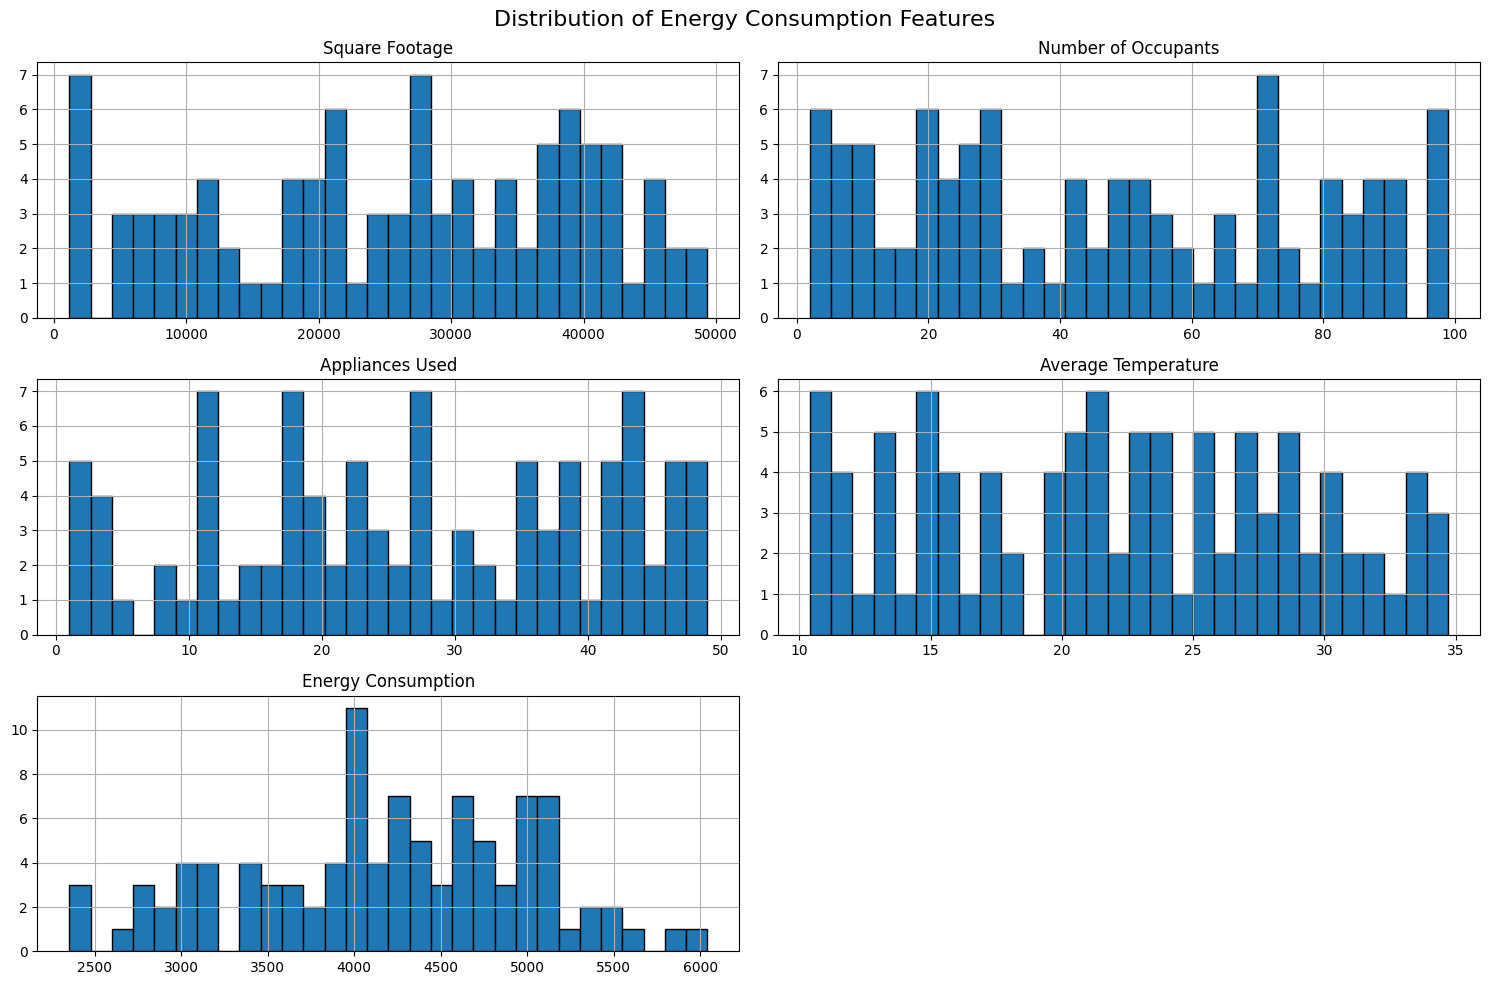

In [ ]:
# Distribution Analysis
Train.hist(figsize=(15, 10), bins=30, edgecolor='black')

plt.suptitle("Distribution of Energy Consumption Features", fontsize=16)
plt.tight_layout()
plt.show()

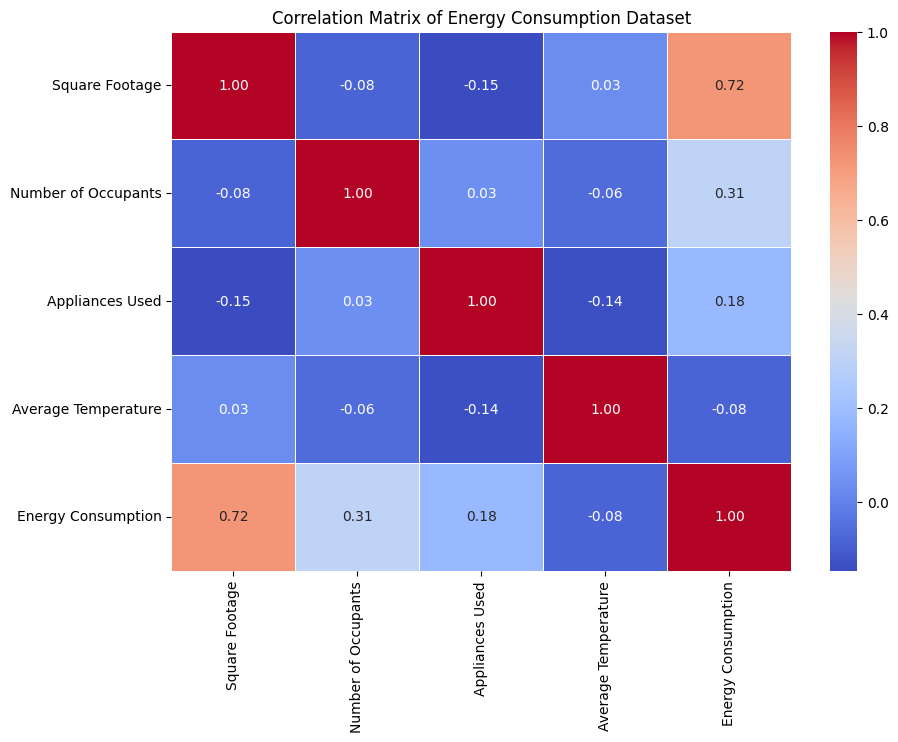

In [ ]:
# Correlation Analysis

correlation = Train.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Energy Consumption Dataset")
plt.show()

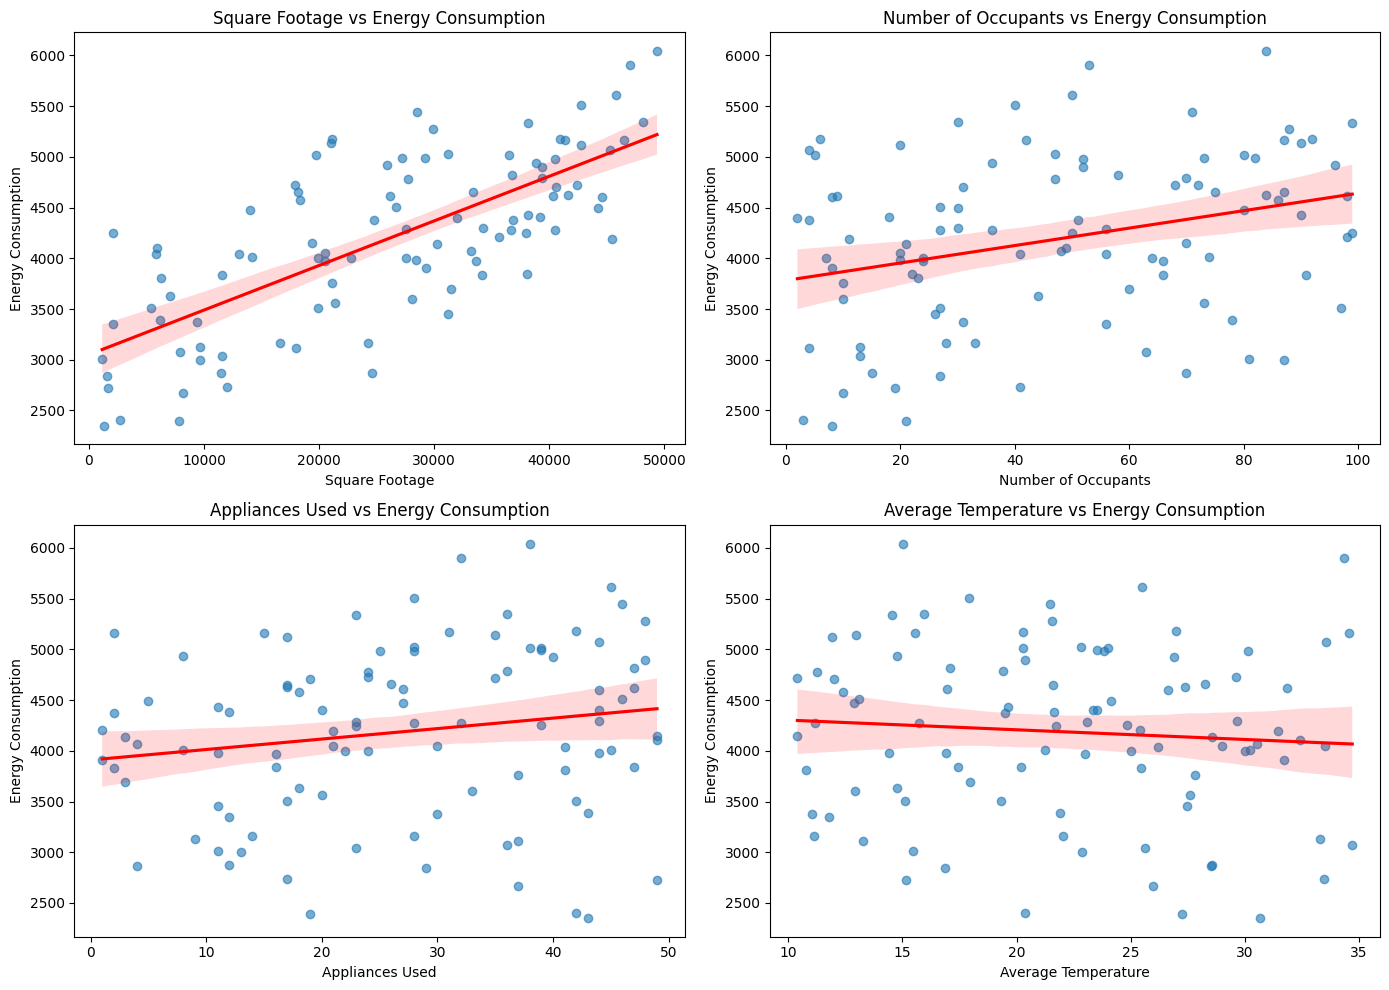

In [ ]:
# Feature vs Target Visualization

features = [
    'Square Footage',
    'Number of Occupants',
    'Appliances Used',
    'Average Temperature'
]

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 2, i)

    sns.regplot(
        data=Train,
        x=feature,
        y='Energy Consumption',
        scatter_kws={'alpha': 0.6},
        line_kws={'color': 'red'}
    )

    plt.title(f'{feature} vs Energy Consumption')
    plt.xlabel(feature)
    plt.ylabel('Energy Consumption')

plt.tight_layout()
plt.show()

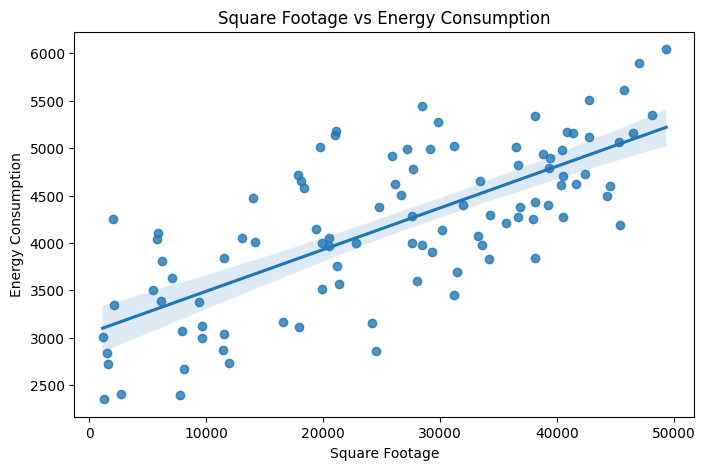

In [ ]:
# Creating scatter plot
plt.figure(figsize=(8, 5))

# Showing relationship between building size and energy consumption
sns.regplot(
    data=Train,
    x='Square Footage',
    y='Energy Consumption'
)

# Adding graph title and axis labels
plt.title('Square Footage vs Energy Consumption')
plt.xlabel('Square Footage')
plt.ylabel('Energy Consumption')

# Displaying the graph
plt.show()

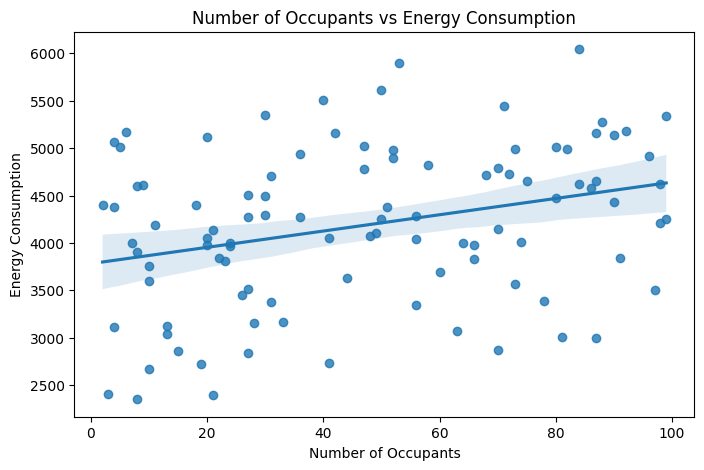

In [ ]:
# Creating a scatter plot for Occupants vs Energy Consumption

plt.figure(figsize=(8, 5))

# Plotting the relationship with a regression line
sns.regplot(
    data=Train,
    x='Number of Occupants',
    y='Energy Consumption'
)

# Adding title and axis labels
plt.title('Number of Occupants vs Energy Consumption')
plt.xlabel('Number of Occupants')
plt.ylabel('Energy Consumption')

# Displaying the plot
plt.show()

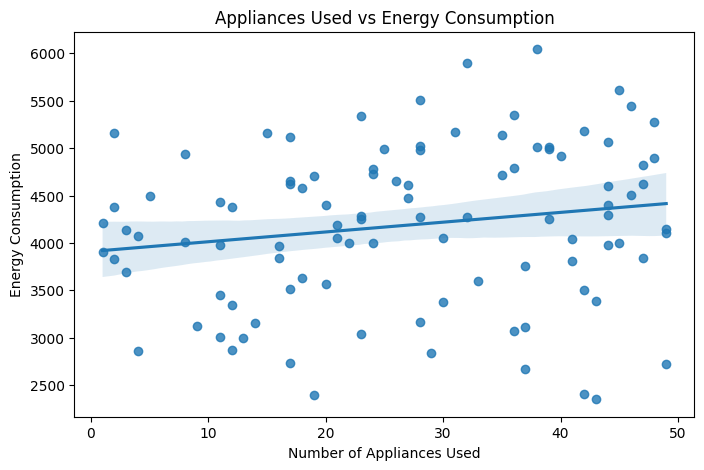

In [ ]:
# Creating a scatter plot for Appliances Used vs Energy Consumption

plt.figure(figsize=(8, 5))

# Plotting the relationship with a regression line
sns.regplot(
    data=Train,
    x='Appliances Used',
    y='Energy Consumption'
)

# Adding title and axis labels
plt.title('Appliances Used vs Energy Consumption')
plt.xlabel('Number of Appliances Used')
plt.ylabel('Energy Consumption')

# Displaying the plot
plt.show()

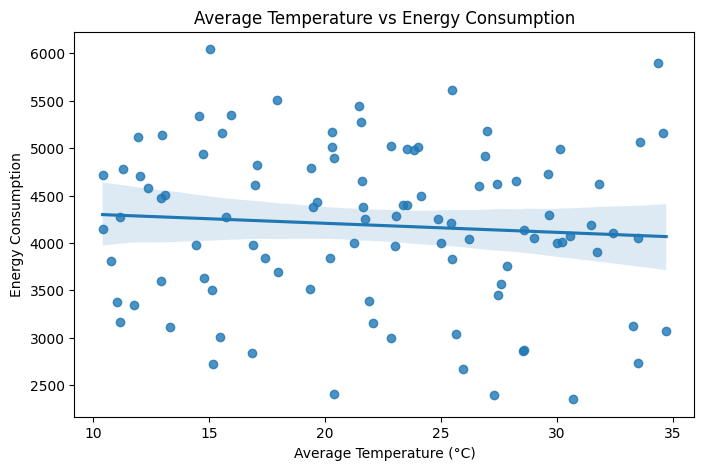

In [ ]:
# Creating a scatter plot for Average Temperature vs Energy Consumption

plt.figure(figsize=(8, 5))

# Plotting the relationship with a regression line
sns.regplot(
    data=Train,
    x='Average Temperature',
    y='Energy Consumption'
)

# Adding title and axis labels
plt.title('Average Temperature vs Energy Consumption')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('Energy Consumption')

# Displaying the plot
plt.show()

In [ ]:
# Calculating correlation of all numerical features with Energy Consumption

correlation = Train.corr(numeric_only=True)['Energy Consumption']

# Sorting correlations from highest to lowest
correlation = correlation.sort_values(ascending=False)

# Removing Energy Consumption's correlation with itself
correlation = correlation.drop('Energy Consumption')


In [ ]:
# Displaying correlation values
print("Correlation with Energy Consumption:")
print(correlation)

Correlation with Energy Consumption:
Square Footage         0.724039
Number of Occupants    0.308594
Appliances Used        0.176380
Average Temperature   -0.079733
Name: Energy Consumption, dtype: float64


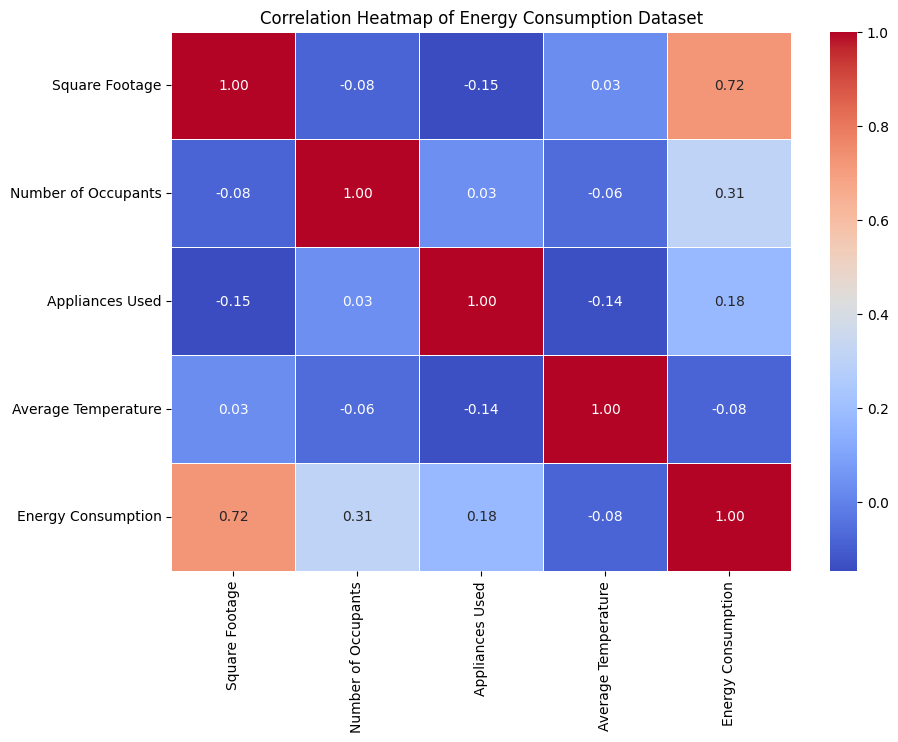

In [ ]:
# Selecting numerical columns for correlation analysis
correlation_matrix = Train.corr(numeric_only=True)

# Creating the figure
plt.figure(figsize=(10, 7))

# Creating the correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# Adding chart title
plt.title('Correlation Heatmap of Energy Consumption Dataset')

# Displaying the heatmap
plt.show()

In [ ]:
# Recalculating the complete Pearson correlation matrix

correlation_matrix = Train.corr(numeric_only=True)

# Displaying correlations with the target variable
print("Correlation with Energy Consumption:")

print(
    correlation_matrix['Energy Consumption']
    .sort_values(ascending=False)
)

# Displaying correlations among independent features
print("\nCorrelation among independent features:")

features = [
    'Square Footage',
    'Number of Occupants',
    'Appliances Used',
    'Average Temperature'
]

print(correlation_matrix.loc[features, features])

Correlation with Energy Consumption:
Energy Consumption     1.000000
Square Footage         0.724039
Number of Occupants    0.308594
Appliances Used        0.176380
Average Temperature   -0.079733
Name: Energy Consumption, dtype: float64

Correlation among independent features:
                     Square Footage  Number of Occupants  Appliances Used  \
Square Footage             1.000000            -0.080458        -0.145933   
Number of Occupants       -0.080458             1.000000         0.034320   
Appliances Used           -0.145933             0.034320         1.000000   
Average Temperature        0.030612            -0.063608        -0.136386   

                     Average Temperature  
Square Footage                  0.030612  
Number of Occupants            -0.063608  
Appliances Used                -0.136386  
Average Temperature             1.000000  


In [ ]:
# Importing the VIF calculation function
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Selecting independent numerical features
X = Train[
    [
        'Square Footage',
        'Number of Occupants',
        'Appliances Used',
        'Average Temperature'
    ]
]

# Creating a VIF results table
vif_data = pd.DataFrame()

# Storing feature names
vif_data['Feature'] = X.columns

# Calculating VIF for each feature
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# Displaying VIF results
print(vif_data)

               Feature       VIF
0       Square Footage  1.027787
1  Number of Occupants  1.010545
2      Appliances Used  1.040505
3  Average Temperature  1.022618


In [ ]:
# Importing train-test split function
from sklearn.model_selection import train_test_split

# Selecting independent features
X = Train[
    [
        'Square Footage',
        'Number of Occupants',
        'Appliances Used',
        'Average Temperature'
    ]
]

# Selecting the target variable
y = Train['Energy Consumption']

# Splitting data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Displaying dataset dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (80, 4)
Validation features: (20, 4)
Training target: (80,)
Validation target: (20,)


In [ ]:
# Importing Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Creating the Linear Regression model
model = LinearRegression()

# Training the model using training data
model.fit(X_train, y_train)

# Displaying model coefficients
print("Model Intercept:", model.intercept_)

print("\nFeature Coefficients:")

# Showing the coefficient of each feature
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Model Intercept: 2063.9226326204835

Feature Coefficients:
Square Footage: 0.0462
Number of Occupants: 10.7838
Appliances Used: 17.7631
Average Temperature: -2.2846


In [ ]:
# Importing evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predicting energy consumption on validation data
y_pred = model.predict(X_val)

# Calculating evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

# Displaying model performance
print("Model Evaluation Results")

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

Model Evaluation Results
MAE: 409.1532
MSE: 201096.3082
R2 Score: 0.6985


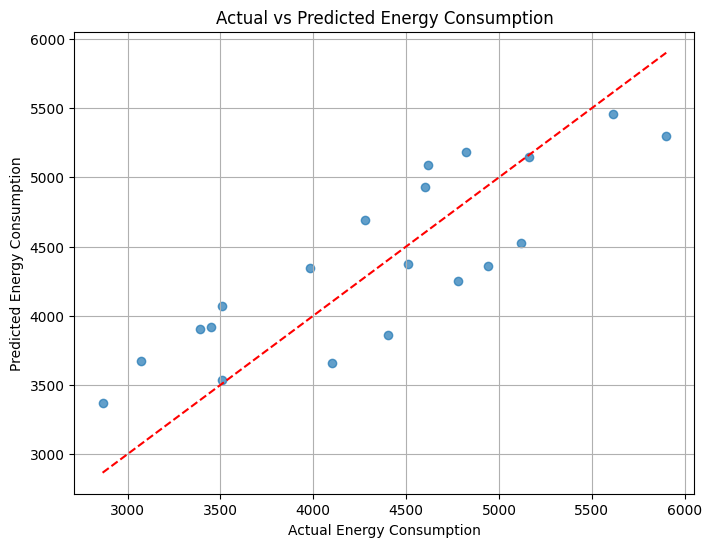

In [ ]:
# Importing Matplotlib for visualization
import matplotlib.pyplot as plt

# Creating a scatter plot of actual and predicted values
plt.figure(figsize=(8, 6))

# Plotting actual values against predicted values
plt.scatter(y_val, y_pred, alpha=0.7)

# Creating a reference line for perfect predictions
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    'r--'
)

# Adding graph labels and title
plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("Actual vs Predicted Energy Consumption")

# Displaying the graph
plt.grid(True)
plt.show()

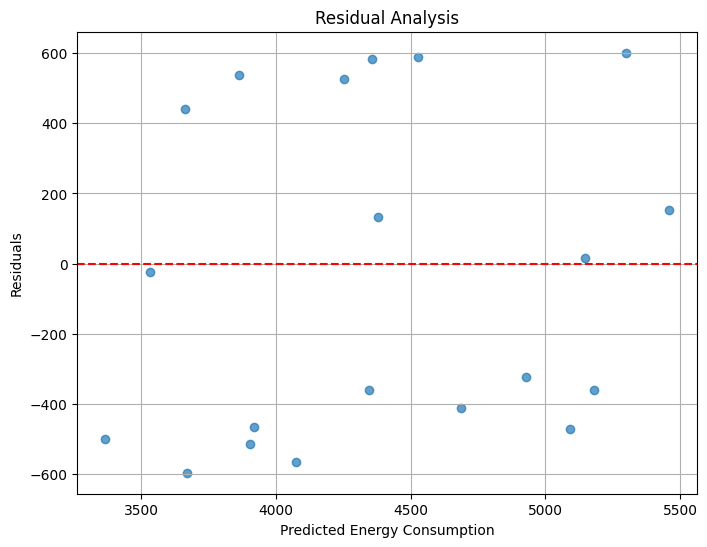

In [ ]:
# Calculating residuals (actual minus predicted)
residuals = y_val - y_pred

# Creating a residual plot
plt.figure(figsize=(8, 6))

# Plotting predicted values against residuals
plt.scatter(y_pred, residuals, alpha=0.7)

# Adding a horizontal zero-error reference line
plt.axhline(y=0, color='red', linestyle='--')

# Adding graph labels and title
plt.xlabel("Predicted Energy Consumption")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

# Displaying the graph
plt.grid(True)
plt.show()

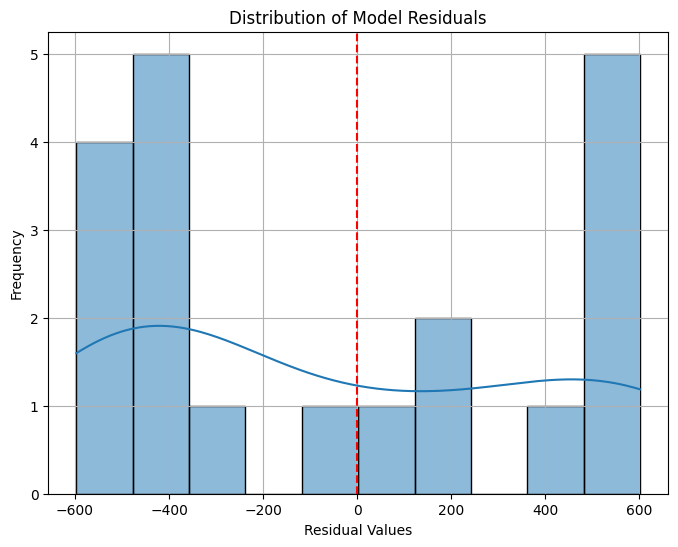

In [ ]:
# Importing visualization library
import seaborn as sns
import matplotlib.pyplot as plt

# Creating a figure for residual distribution
plt.figure(figsize=(8, 6))

# Plotting the distribution of residuals
sns.histplot(
    residuals,
    kde=True,
    bins=10
)

# Adding a reference line at zero
plt.axvline(
    x=0,
    color='red',
    linestyle='--'
)

# Adding graph labels and title
plt.xlabel("Residual Values")
plt.ylabel("Frequency")
plt.title("Distribution of Model Residuals")

# Displaying the graph
plt.grid(True)
plt.show()

In [ ]:
# Importing Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Creating the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=None
)

# Training the model using training data
rf_model.fit(X_train, y_train)

# Predicting energy consumption on validation data
rf_pred = rf_model.predict(X_val)

# Displaying the first five predictions
print("Random Forest Predictions:")
print(rf_pred[:5])

Random Forest Predictions:
[5113.3806 3526.1534 3500.6615 3927.8037 4545.1788]


In [ ]:
# Importing evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluating Linear Regression
lr_mae = mean_absolute_error(y_val, y_pred)
lr_mse = mean_squared_error(y_val, y_pred)
lr_r2 = r2_score(y_val, y_pred)

# Evaluating Random Forest
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_mse = mean_squared_error(y_val, rf_pred)
rf_r2 = r2_score(y_val, rf_pred)

# Displaying model comparison
print("Linear Regression vs Random Forest")
print("-----------------------------------")

print(f"Linear Regression MAE: {lr_mae:.4f}")
print(f"Random Forest MAE:     {rf_mae:.4f}")

print(f"\nLinear Regression MSE: {lr_mse:.4f}")
print(f"Random Forest MSE:     {rf_mse:.4f}")

print(f"\nLinear Regression R2:  {lr_r2:.4f}")
print(f"Random Forest R2:      {rf_r2:.4f}")

Linear Regression vs Random Forest
-----------------------------------
Linear Regression MAE: 409.1532
Random Forest MAE:     456.9508

Linear Regression MSE: 201096.3082
Random Forest MSE:     265632.4761

Linear Regression R2:  0.6985
Random Forest R2:      0.6017


In [ ]:
# Importing Pandas for creating a feature importance table
import pandas as pd

# Extracting feature importance from Random Forest
importance = rf_model.feature_importances_

# Creating a DataFrame for feature importance
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sorting features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Displaying feature importance
print(importance_df)

               Feature  Importance
0       Square Footage    0.644410
1  Number of Occupants    0.166992
2      Appliances Used    0.127188
3  Average Temperature    0.061410


In [ ]:
# Importing permutation importance function
from sklearn.inspection import permutation_importance

# Calculating permutation importance on validation data
perm_importance = permutation_importance(
    rf_model,
    X_val,
    y_val,
    n_repeats=30,
    random_state=42,
    scoring='r2'
)

# Creating a DataFrame for permutation importance
perm_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
})

# Sorting features by importance
perm_importance_df = perm_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Displaying the results
print(perm_importance_df)

               Feature  Importance       Std
0       Square Footage    1.163871  0.284143
1  Number of Occupants    0.157823  0.102691
2      Appliances Used    0.040503  0.047592
3  Average Temperature   -0.019246  0.019700


In [ ]:
# Importing cross-validation function
from sklearn.model_selection import cross_val_score

# Creating a Random Forest model
rf_cv_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Performing 5-Fold Cross-Validation using R2 score
cv_scores = cross_val_score(
    rf_cv_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

# Displaying individual fold scores
print("5-Fold Cross-Validation R2 Scores:")
for fold, score in enumerate(cv_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

# Calculating mean and standard deviation
print("\nCross-Validation Results")
print(f"Mean R2 Score: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

5-Fold Cross-Validation R2 Scores:
Fold 1: 0.6970
Fold 2: 0.6650
Fold 3: 0.6197
Fold 4: 0.6771
Fold 5: 0.5895

Cross-Validation Results
Mean R2 Score: 0.6497
Standard Deviation: 0.0394


In [ ]:
# Importing Linear Regression model
from sklearn.linear_model import LinearRegression

# Creating the Linear Regression model
lr_cv_model = LinearRegression()

# Performing 5-Fold Cross-Validation
lr_cv_scores = cross_val_score(
    lr_cv_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

# Displaying individual fold scores
print("Linear Regression 5-Fold R2 Scores:")

for fold, score in enumerate(lr_cv_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

# Displaying mean and standard deviation
print("\nCross-Validation Results")
print(f"Mean R2 Score: {lr_cv_scores.mean():.4f}")
print(f"Standard Deviation: {lr_cv_scores.std():.4f}")

Linear Regression 5-Fold R2 Scores:
Fold 1: 0.7099
Fold 2: 0.7820
Fold 3: 0.5804
Fold 4: 0.7590
Fold 5: 0.5887

Cross-Validation Results
Mean R2 Score: 0.6840
Standard Deviation: 0.0845


In [ ]:
# Import required libraries
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Create two models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# Compare both models using 5-fold cross-validation
for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=5,
        scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]
    )

    # Calculate average performance
    print("\nModel:", name)
    print("Mean R2:", round(scores["test_r2"].mean(), 4))
    print("Mean MAE:", round(-scores["test_neg_mean_absolute_error"].mean(), 2))
    print("Mean RMSE:", round(-scores["test_neg_root_mean_squared_error"].mean(), 2))


Model: Linear Regression
Mean R2: 0.684
Mean MAE: 402.19
Mean RMSE: 453.88

Model: Random Forest
Mean R2: 0.6497
Mean MAE: 411.84
Mean RMSE: 482.32


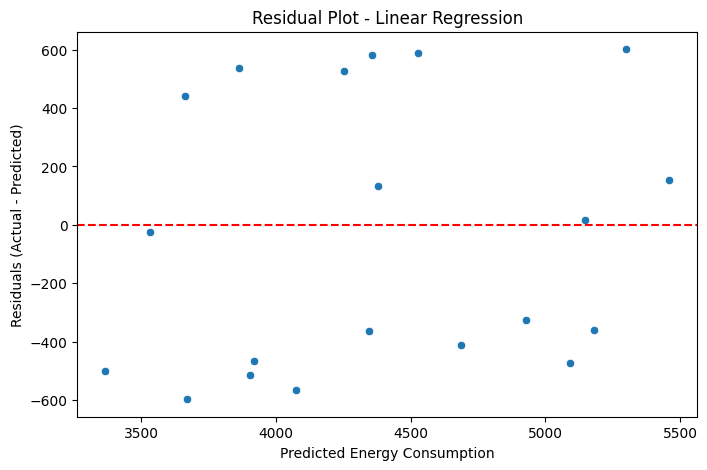

In [ ]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Train Linear Regression using training split
model = LinearRegression()
model.fit(X_train, y_train)

# Predict validation data
lr_pred = model.predict(X_val)

# Calculate residuals
residuals = y_val - lr_pred

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

sns.scatterplot(x=lr_pred, y=residuals)

# Add zero reference line
plt.axhline(y=0, color='red', linestyle='--')

# Add chart labels
plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Energy Consumption")
plt.ylabel("Residuals (Actual - Predicted)")

plt.show()

In [ ]:
# Import Breusch-Pagan test
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

# Add constant to validation features
X_val_const = sm.add_constant(X_val)

# Perform Breusch-Pagan test
bp_test = het_breuschpagan(residuals, X_val_const)

# Extract test results
labels = ["LM Statistic", "LM-Test p-value",
          "F-Statistic", "F-Test p-value"]

# Display results
for label, value in zip(labels, bp_test):
    print(label, ":", round(value, 4))

LM Statistic : 3.4703
LM-Test p-value : 0.4824
F-Statistic : 0.7873
F-Test p-value : 0.5511


In [ ]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Select input features from the complete training dataset
X_final = Train[
    [
        'Square Footage',
        'Number of Occupants',
        'Appliances Used',
        'Average Temperature'
    ]
]

# Select target variable
y_final = Train['Energy Consumption']

# Create and train the final model
final_model = LinearRegression()
final_model.fit(X_final, y_final)

# Prepare test data using the same features
X_test = Test[
    [
        'Square Footage',
        'Number of Occupants',
        'Appliances Used',
        'Average Temperature'
    ]
]

# Predict energy consumption for test data
test_predictions = final_model.predict(X_test)

# Display the first 10 predictions
print("First 10 Predictions:")
print(test_predictions[:10])

# Display total number of predictions
print("\nTotal Predictions:", len(test_predictions))

First 10 Predictions:
[3398.75373873 4288.6248933  4903.69195978 5128.05927465 5165.2593273
 4454.55626832 4803.98873513 2897.91459323 3513.34026909 4558.79181303]

Total Predictions: 100


In [ ]:
# Display test dataset columns
print("Test Dataset Columns:")
print(Test.columns.tolist())

# Display first five rows
print("\nFirst 5 Rows:")
print(Test.head())

Test Dataset Columns:
['Building Type', 'Square Footage', 'Number of Occupants', 'Appliances Used', 'Average Temperature', 'Day of Week', 'Energy Consumption']

First 5 Rows:
  Building Type  Square Footage  Number of Occupants  Appliances Used  \
0   Residential           24563                   15                4   
1    Commercial           27583                   56               23   
2    Commercial           45313                    4               44   
3   Residential           41625                   84               17   
4   Residential           36720                   58               47   

   Average Temperature Day of Week  Energy Consumption  
0                28.52     Weekday             2865.57  
1                23.07     Weekend             4283.80  
2                33.56     Weekday             5067.83  
3                27.39     Weekend             4624.30  
4                17.08     Weekday             4820.59  


In [ ]:
# Compare actual and predicted energy consumption
comparison = Test[['Energy Consumption']].copy()

# Add model predictions
comparison['Predicted Energy Consumption'] = test_predictions

# Calculate prediction errors
comparison['Error'] = (
    comparison['Energy Consumption'] -
    comparison['Predicted Energy Consumption']
)

# Display first 10 comparisons
print(comparison.head(10).round(2))

# Calculate test performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("\nTest MAE:", round(mean_absolute_error(
    comparison['Energy Consumption'],
    comparison['Predicted Energy Consumption']
), 2))

print("Test RMSE:", round(np.sqrt(mean_squared_error(
    comparison['Energy Consumption'],
    comparison['Predicted Energy Consumption']
)), 2))

print("Test R2:", round(r2_score(
    comparison['Energy Consumption'],
    comparison['Predicted Energy Consumption']
), 4))


   Energy Consumption  Predicted Energy Consumption   Error
0             2865.57                       3398.75 -533.18
1             4283.80                       4288.62   -4.82
2             5067.83                       4903.69  164.14
3             4624.30                       5128.06 -503.76
4             4820.59                       5165.26 -344.67
5             5026.23                       4454.56  571.67
6             4404.56                       4803.99 -399.43
7             2394.37                       2897.91 -503.54
8             3969.09                       3513.34  455.75
9             5136.69                       4558.79  577.90

Test MAE: 377.66
Test RMSE: 423.9
Test R2: 0.7381
